### This book shows how we fill library, and here we will collect results 

What should our tensors include?
Features which describe size of catenary curves, transmissions and phase shift.

Подумаем от каких параметров меняется форма ячейки.
1. Мы можем изменять высоту ячейки H, но это не типичный параметр для вариации
2. Мы можем менять изгиб 'a', что влияет на скорость смещения центра. Мы можем изменять зависимость расстояния между верхней и нижней кривой. Сейчас это константа для одной формы. Если это не будет константой, то нужно будет менять способ расчета сечений.
Итого, получаем высота - не изменяемый параметр для всей библиотеки. y_center зависит а. Итого получаем 2 изменяемых параметра при текущей конфигурации.     

In [120]:
import meep as mp
import conf
import matplotlib.pyplot as plt
import numpy as np

In [121]:
pml_layers = [mp.PML(thickness=conf.in_pml, direction=mp.X)]
cell = mp.Vector3(conf.cell_X, conf.cell_Y, 0)
symmetries = [mp.Mirror(mp.Y)]
geometry = [mp.Block(
    material=conf.in_material,
    size=mp.Vector3(conf.in_sub, mp.inf, conf.cell_Z),
    center=conf.sub_center,
)]
sources = [mp.Source(
    mp.ContinuousSource(conf.inc_fcen, fwidth=conf.inc_df),
    component=mp.Ez,
    center=conf.source_center,
    size=mp.Vector3(x=0, y=conf.cell_Y, z=conf.cell_Z),
)]

sim = mp.Simulation(
    cell_size=cell,
    boundary_layers=pml_layers,
    geometry=geometry,
    sources=sources,
    resolution=conf.resolution,
    symmetries = symmetries,
)
flux_obj = sim.add_flux(
            conf.inc_fcen, 0, 1, mp.FluxRegion(center=conf.flux_center, size=mp.Vector3(y=conf.cell_Y, z=conf.cell_Z))
)
sim.run(until=conf.steps) # run 1st part of simulation
input_flux = mp.get_fluxes(flux_obj) # saving flux from sub in input_flux
sim.reset_meep() # purge all adjustments of simulation

-----------
Initializing structure...
Halving computational cell along direction y
time for choose_chunkdivision = 0.00116682 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.00930381 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)


In [122]:
step = 5
mode_tran = np.empty(step)
mode_phase = np.empty(step)
size_block = [None] * step  # Список для объектов mp.Vector3
min_width, max_width = 0.3, 2
min_a, max_a = 0.5, 3

# Параметры цепной линии
a = np.linspace(min_a, max_a, step)  # параметр формы цепной линии
width = np.linspace(min_width, max_width, step) # параметр ширины цепной линии
x_max = 1  # диапазон x
x_min = -x_max
number_sections = 1
x_sections = np.linspace(0, x_max,  number_sections, endpoint=False) # В этих точках будем вычислять значения для y1 and y2
geometry.append(mp.Block(
    material=conf.at_material,
    size=mp.Vector3(0,0,0),
    center=mp.Vector3(0,0,0),
))

In [123]:
width[4]

2.0

0.3
-----------
Initializing structure...
time for choose_chunkdivision = 0.00040102 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0,0,0)
          size (2,0.3,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.0136118 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)
MPB solved for frequency_1(0.333333,0,0) = 0.333333 after 13 iters
Dominant planewave for band 1: (0.333333,-0.000000,0.000000)
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0,0,0)
          size (2,0.3,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


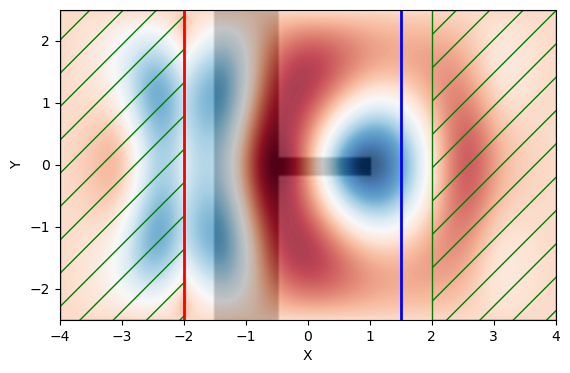

0.725
-----------
Initializing structure...
time for choose_chunkdivision = 3.38554e-05 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0,0,0)
          size (2,0.725,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.0137529 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)
MPB solved for frequency_1(0.333333,0,0) = 0.333333 after 13 iters
Dominant planewave for band 1: (0.333333,-0.000000,0.000000)
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0,0,0)
          size (2,0.725,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


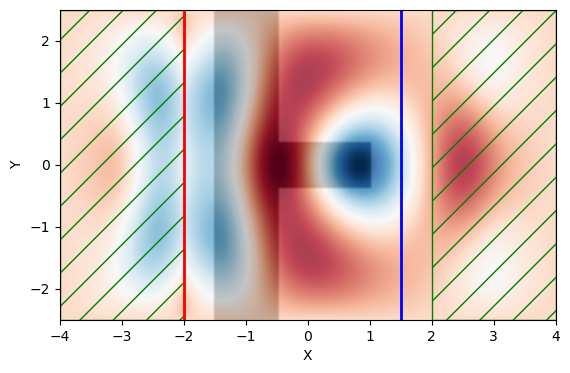

1.15
-----------
Initializing structure...
time for choose_chunkdivision = 2.69413e-05 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0,0,0)
          size (2,1.15,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.0133159 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)
MPB solved for frequency_1(0.333333,0,0) = 0.333333 after 13 iters
Dominant planewave for band 1: (0.333333,-0.000000,0.000000)
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0,0,0)
          size (2,1.15,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


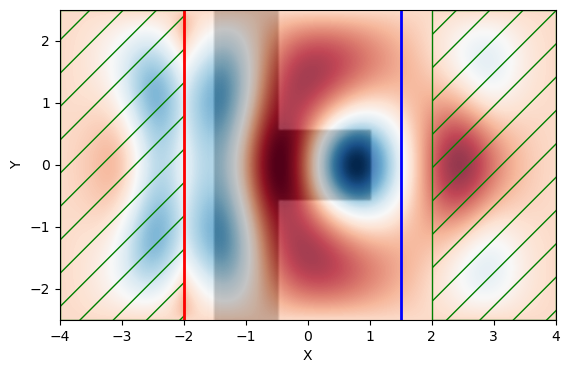

1.575
-----------
Initializing structure...
time for choose_chunkdivision = 2.7895e-05 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0,0,0)
          size (2,1.575,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.0137529 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)
MPB solved for frequency_1(0.333333,0,0) = 0.333333 after 13 iters
Dominant planewave for band 1: (0.333333,-0.000000,0.000000)
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0,0,0)
          size (2,1.575,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


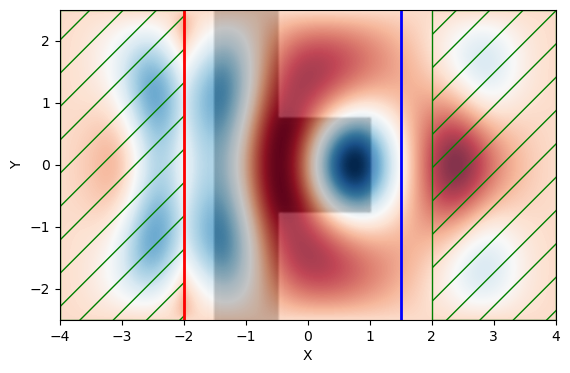

2.0
-----------
Initializing structure...
time for choose_chunkdivision = 3.00407e-05 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0,0,0)
          size (2,2,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.0141511 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)
MPB solved for frequency_1(0.333333,0,0) = 0.333333 after 13 iters
Dominant planewave for band 1: (0.333333,-0.000000,0.000000)
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0,0,0)
          size (2,2,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


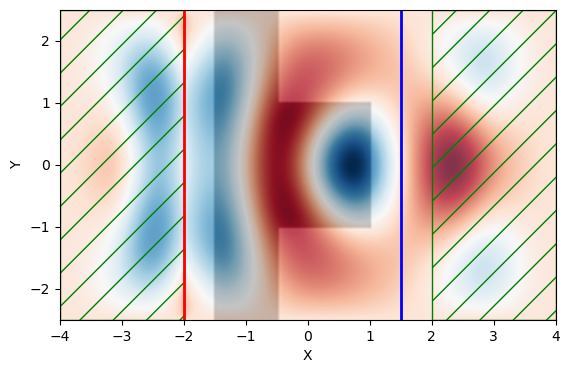

In [124]:
for j in range(step):
    size_block[j] = mp.Vector3(x=conf.at_hei, y=width[j])
    print(width[j])
    for i in range(number_sections): #фактически номер секции сейчас не используется, и это просто заготовка. Внутри код где-то это не учитывает
        y_center = a[i] * np.cosh(x_sections[i] / a[i]) - a[i] 
        geometry[1].size = size_block[j]
        geometry[1].center =mp.Vector3(y=y_center)
        
        sim = mp.Simulation(
            cell_size=cell,
            boundary_layers=pml_layers,
            geometry=geometry,
            sources=sources,
            resolution=conf.resolution,
        )
        flux_obj = sim.add_flux(
            conf.inc_fcen, 0, 1, mp.FluxRegion(
                center=mp.Vector3(x=conf.flux_center[0]), 
                size=mp.Vector3(y=conf.cell_Y)
            )
        )
        sim.run(until=conf.steps)
        
        res = sim.get_eigenmode_coefficients(
            flux_obj, [1], eig_parity=mp.ODD_Z + mp.EVEN_Y
        )
        coeffs = res.alpha
        
        mode_tran[j] = abs(coeffs[0, 0, 0]) ** 2 / input_flux[0]
        mode_phase[j] = np.angle(coeffs[0, 0, 0])
        if mode_phase[j] > 0:
            mode_phase[j] -= 2 * np.pi
        
        %matplotlib inline
        plt.figure(dpi=100)
        sim.plot2D(fields=mp.Ez)
        plt.show()
        sim.reset_meep() # purge all adjustments of simulation
            

In [130]:
mode_phase, mode_tran

(array([-4.45787766, -4.15662154, -3.67216154, -3.30865309, -3.25395803]),
 array([0.34706167, 0.13781111, 0.07463857, 0.0851662 , 0.1296801 ]))

In [126]:
width

array([0.3  , 0.725, 1.15 , 1.575, 2.   ])

In [128]:
a

array([0.5  , 1.125, 1.75 , 2.375, 3.   ])